# MINT EQ Method

## 1. Load The RIR

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import librosa

rir_path = Path("../data/RIR.wav")

y, sr = librosa.load(rir_path, sr=None)

if y.ndim == 1:
    y = y[np.newaxis, :]
    n_channels = 1
else:
    n_channels = y.shape[0]

duration_s = y.shape[1] / sr
n_samples = y.shape[1]


print("=== Impulse Response Metadata ===")
print(f"Sample rate:     {sr} Hz")
print(f"Channels:       {n_channels}")
print(f"Samples:        {n_samples}")
print(f"Duration:       {duration_s:.4f} s ({duration_s*1000:.2f} ms)")
print(f"Shape:          {y.shape}")

print("=== Channel Statistics ===")
for ch in range(n_channels):
    samples = y[ch]
    print(f"Channel {ch+1}:")
    print(f"  Max amplitude:  {np.max(np.abs(samples)):.6f}")
    print(f"  RMS:            {np.sqrt(np.mean(samples**2)):.6f}")
    print(f"  Peak index:     {np.argmax(np.abs(samples))} (t = {np.argmax(np.abs(samples))/sr*1000:.2f} ms)")



=== Impulse Response Metadata ===
Sample rate:     48000 Hz
Channels:       1
Samples:        20944
Duration:       0.4363 s (436.33 ms)
Shape:          (1, 20944)
=== Channel Statistics ===
Channel 1:
  Max amplitude:  0.990000
  RMS:            0.039588
  Peak index:     210 (t = 4.38 ms)


## 2. Normalize RIR

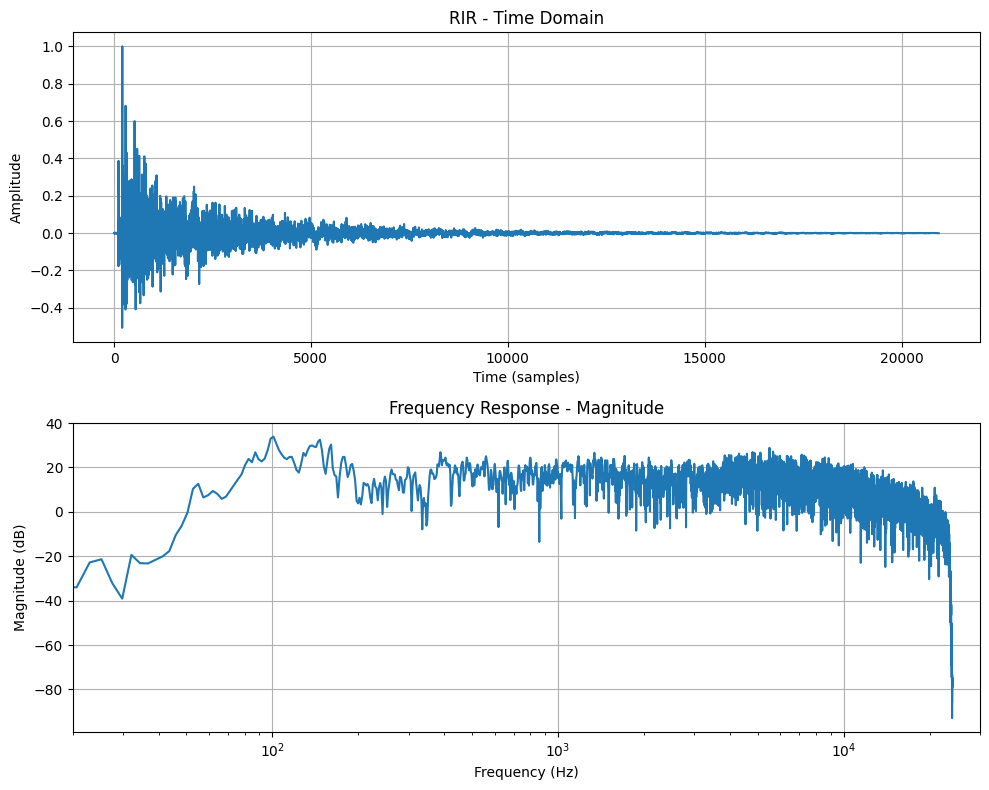

In [2]:
# Get first channel as 1D array
H = y[0]

# Normalize the RIR
H = H / np.max(np.abs(H))

# Compute frequency response
N = len(H)
H_fft = np.fft.fft(H, N)
freq = np.arange(N) * sr / N

# Get magnitude and phase
magnitude = np.abs(H_fft)
magnitude_db = 20 * np.log10(magnitude + np.finfo(float).eps)  # Add eps to avoid log(0)
phase = np.angle(H_fft)

# Plot all in one figure
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# Time domain RIR
axes[0].plot(H)
axes[0].set_title('RIR - Time Domain')
axes[0].set_xlabel('Time (samples)')
axes[0].set_ylabel('Amplitude')
axes[0].grid(True)

# Magnitude response (log scale)
axes[1].semilogx(freq[1:N//2 + 1], magnitude_db[1:N//2 + 1])
axes[1].set_title('Frequency Response - Magnitude')
axes[1].set_xlabel('Frequency (Hz)')
axes[1].set_ylabel('Magnitude (dB)')
axes[1].grid(True)
axes[1].set_xlim([20, 30000])

plt.tight_layout()
plt.show()

## 3. Filter Design: MINT-2

The MINT least-squares inverse is computed in the frequency domain using FFTs — O(N log N) time, O(N) memory — instead of building a dense N x N Toeplitz matrix and solving with `lstsq` (O(N^3) time, O(N^2) memory).

3.5GB

### Performance

- **No Toeplitz matrix** — in-place FFT operations on 1D arrays, O(N) memory
- **FFT-based solve** — O(N log N) instead of O(N^3)
- **Power-of-2 FFT length** — `L_fft = 1 << ceil(log2(L))` ensures optimal radix
- **`rfft`/`irfft`** — exploits real-valued signals, ~2x faster and half the memory vs complex `fft`
- **`H_power` reuse** — |H(f)|^2 computed once for both regularisation and the inverse

### Regularisation

Tikhonov regularisation with $\beta = 10^{-6} \cdot \max|H(f)|^2$ prevents blow-up at frequencies where H is near zero. This gives the standard regularised MINT solution:

$$W(f) = \frac{H^*(f)}{|H(f)|^2 + \beta}$$


In [3]:
# MINT: Multiple-input/output INverse-filtering Theorem
# For SISO case: Design inverse filter W such that H * W ≈ D (impulse)
#
# Frequency-domain formulation of the Tikhonov-regularised least-squares problem:
#   min_W ||H*W - δ||² + β||W||²
# Solution:  W(f) = H*(f) / (|H(f)|² + β)

from scipy.io import wavfile

H = np.asarray(H).ravel()
M = N  # inverse-filter length (≥ RIR length)

# Linear convolution length, padded to next power-of-2 for FFT speed
L = N + M - 1
L_fft = 1 << int(np.ceil(np.log2(L)))

# rfft is ~2x faster than fft for real-valued signals
H_fft = np.fft.rfft(H, n=L_fft)
H_power = np.abs(H_fft) ** 2

# Tikhonov regularisation (small fraction of peak spectral energy)
beta = 1e-9 * np.max(H_power)

# MINT inverse filter: W(f) = H*(f) / (|H(f)|² + β)
W_fft = np.conj(H_fft) / (H_power + beta)
W = np.fft.irfft(W_fft, n=L_fft)[:M]

# Verify: equalized IR should approximate a unit impulse
EQ_fft = H_fft * np.fft.rfft(W, n=L_fft)
H_equalized = np.fft.irfft(EQ_fft, n=L_fft)[:N]

D = np.zeros(N)
D[0] = 1.0
error_norm = np.linalg.norm(H_equalized - D)
print(f'Filter design verification error: {error_norm:.6e}')

# Save the Equalized IR as a WAV file
H_equalized_norm = H_equalized / np.max(np.abs(H_equalized))
equalized_ir_path = rir_path.parent / 'MINT-2-EIR.wav'
wavfile.write(str(equalized_ir_path), int(sr), H_equalized_norm.astype(np.float32))
print(f'Equalized IR saved to: {equalized_ir_path}')

Filter design verification error: 1.411100e+00
Equalized IR saved to: ../data/MINT-2-EIR.wav


## 4. Compare EIR Magnitude Responses

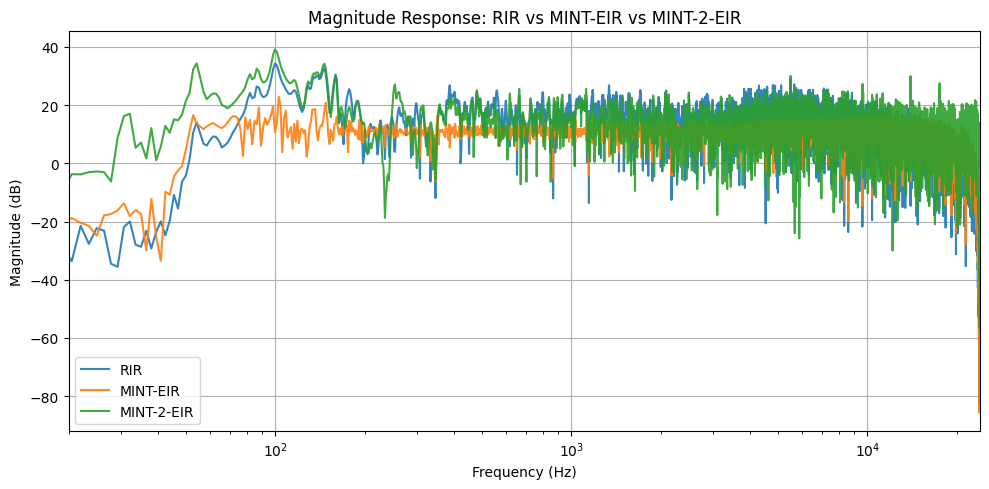

In [4]:
data_dir = rir_path.parent

# Load both EIRs
eir_mint, sr_mint = librosa.load(data_dir / 'MINT-EIR.wav', sr=None)
eir_mint2, sr_mint2 = librosa.load(data_dir / 'MINT-2-EIR.wav', sr=None)

# Ensure 1D
eir_mint = np.asarray(eir_mint).ravel()
eir_mint2 = np.asarray(eir_mint2).ravel()

# Compute magnitude response (dB)
n1, n2 = len(eir_mint), len(eir_mint2)
n_fft = max(n1, n2, len(H))
n_fft = 1 << int(np.ceil(np.log2(n_fft)))

mag_rir = np.abs(np.fft.rfft(H, n=n_fft))
mag_rir_db = 20 * np.log10(mag_rir + np.finfo(float).eps)

mag_mint = np.abs(np.fft.rfft(eir_mint, n=n_fft))
mag_mint_db = 20 * np.log10(mag_mint + np.finfo(float).eps)

mag_mint2 = np.abs(np.fft.rfft(eir_mint2, n=n_fft))
mag_mint2_db = 20 * np.log10(mag_mint2 + np.finfo(float).eps)

freq = np.fft.rfftfreq(n_fft, 1 / sr_mint)
n_pos = len(freq)  # rfft: 0 .. Nyquist

# Plot comparison: RIR (reference) first, then EIRs. Last plotted = on top when overlapping.
fig, ax = plt.subplots(figsize=(10, 5))
ax.semilogx(freq[1:n_pos], mag_rir_db[1:n_pos], label='RIR', alpha=0.9)
ax.semilogx(freq[1:n_pos], mag_mint_db[1:n_pos], label='MINT-EIR', alpha=0.9)
ax.semilogx(freq[1:n_pos], mag_mint2_db[1:n_pos], label='MINT-2-EIR', alpha=0.9)
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Magnitude (dB)')
ax.set_title('Magnitude Response: RIR vs MINT-EIR vs MINT-2-EIR')
ax.set_xlim([20, min(24000, sr_mint / 2)])
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

### Why MINT-2 May Perform Worse

The second method (MINT-2, FFT + Tikhonov) can perform worse than the original Toeplitz-based MINT for these reasons:

**1. Regularization bias**

The Tikhonov term $\beta\|W\|^2$ penalizes large filter coefficients. That improves conditioning but biases the solution away from the true inverse, so the equalized response is less sharp than the unregularized least-squares solution.

**2. Different optimization problems**

- **MINT (Toeplitz):** $\min_W \|H_{\text{conv}} W - D\|^2$ — unregularized least squares
- **MINT-2:** $\min_W \|H W - \delta\|^2 + \beta\|W\|^2$ — regularized least squares

These are not the same problem; the regularized one trades accuracy for stability.

**3. $\beta$ may be too large**

With $\beta = 10^{-6} \cdot \max|H|^2$, the regularization can be strong enough to noticeably reduce equalization quality.

### Possible improvements for MINT-2

- **Reduce $\beta$** (e.g. $10^{-8}$ or $10^{-9}$) to get closer to the unregularized inverse
- **Use frequency-dependent regularization** — higher $\beta$ at frequencies where $H$ is very small
- **Keep the original Toeplitz-based MINT** when accuracy matters more than speed